## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)

## 2. Load the cleaned dataset
Place the CSV in the same folder as this notebook. Change the file name below if needed.

In [4]:
df = pd.read_csv(r"C:\Users\akars\OneDrive\Desktop\projects\End-to-End Supply Chain Analytics & Late Delivery Prediction\data\DataCoSupplyChainDataset_Cleaned.csv", encoding="latin1")

# Remove an exported index column if one exists
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (180518, 44)


,Type,Days_for_shipping_(real),Days_for_shipment_(scheduled),Sales_per_customer,Delivery_Status,Late_delivery_risk,Category_Id,Category_Name,Customer_City,Customer_Country,Customer_Fname,Customer_Id,Customer_Lname,Customer_Segment,Customer_State,Customer_Zipcode,Department_Id,Department_Name,Market,Order_City,Order_Country,Order_Customer_Id,order_date_(DateOrders),Order_Id,Order_Item_Cardprod_Id,Order_Item_Discount,Order_Item_Discount_Rate,Order_Item_Id,Order_Item_Product_Price,Order_Item_Profit_Ratio,Order_Item_Quantity,Sales,Order_Item_Total,Order_Profit_Per_Order,Order_Region,Order_State,Order_Status,Product_Card_Id,Product_Category_Id,Product_Name,Product_Price,Product_Status,shipping_date_(DateOrders),Shipping_Mode
0,TRANSFER,5,4,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,Irene,19492,Luna,Consumer,PR,725.0,2,Fitness,Pacific Asia,Bikaner,India,19492,2018-01-13,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,RajastÃ¡n,PENDING,1360,73,Smart watch,327.75,0,2018-01-18,Standard Class
1,CASH,4,4,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,Gillian,19491,Maldonado,Consumer,CA,95125.0,2,Fitness,Pacific Asia,Bikaner,India,19491,2018-01-13,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,RajastÃ¡n,CLOSED,1360,73,Smart watch,327.75,0,2018-01-17,Standard Class
2,DEBIT,3,4,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,Tana,19490,Tate,Home Office,CA,90027.0,2,Fitness,Pacific Asia,Townsville,Australia,19490,2018-01-13,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,Smart watch,327.75,0,2018-01-16,Standard Class
3,PAYMENT,2,4,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,Orli,19489,Hendricks,Corporate,PR,725.0,2,Fitness,Pacific Asia,Townsville,Australia,19489,2018-01-13,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,Smart watch,327.75,0,2018-01-15,Standard Class
4,TRANSFER,6,4,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,EE. UU.,Kimberly,19488,Flowers,Consumer,NY,14150.0,2,Fitness,Pacific Asia,Toowoomba,Australia,19488,2018-01-13,75935,1360,32.779999,0.10,179250,327.75,0.06,1,327.75,294.980011,18.580000,Oceania,Queensland,CANCELED,1360,73,Smart watch,327.75,0,2018-01-19,Standard Class


## 3. Understand the target column
First check the recorded delivery outcomes and the existing risk flag. We will not use the existing risk flag as an input.

In [5]:
print("Delivery status:")
print(df["Delivery_Status"].value_counts(dropna=False))

print("\\nExisting late delivery risk:")
print(df["Late_delivery_risk"].value_counts(dropna=False))

print("\\nDelivery status compared with risk flag:")
display(pd.crosstab(df["Delivery_Status"], df["Late_delivery_risk"], margins=True))

Delivery status:
Delivery_Status
Late delivery        98977
Advance shipping     41591
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64
\nExisting late delivery risk:
Late_delivery_risk
1    98977
0    81541
Name: count, dtype: int64
\nDelivery status compared with risk flag:


Late_delivery_risk,0,1,All
Delivery_Status,,,
Advance shipping,41591,0,41591
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81541,98977,180518


## 4. Create the prediction target

We create a new column named `Late`:
- 1 means late delivery
- 0 means not late delivery

Canceled orders are removed because they are not a completed late/not-late delivery outcome.

In [6]:
valid_status = ["Late delivery", "Advance shipping", "Shipping on time"]

ml_df = df[df["Delivery_Status"].isin(valid_status)].copy()

ml_df["Late"] = (ml_df["Delivery_Status"] == "Late delivery").astype(int)

print("Rows available for modelling:", len(ml_df))
print("Target counts:")
print(ml_df["Late"].value_counts())

print("Target percentage:")
print((ml_df["Late"].value_counts(normalize=True) * 100).round(2))

Rows available for modelling: 172764
Target counts:
Late
1    98977
0    73787
Name: count, dtype: int64
Target percentage:
Late
1    57.29
0    42.71
Name: proportion, dtype: float64


## 5. Select input columns (features)

We deliberately exclude columns that reveal the delivery outcome or are only known after delivery.

We use a small set of understandable order, product, customer, and planned-shipping features. If any column is missing from your cleaned CSV, the code reports it.

In [7]:
features = [
    "Type",
    "Category_Name",
    "Customer_Segment",
    "Department_Name",
    "Market",
    "Order_Region",
    "Shipping_Mode",
    "Days_for_shipment_(scheduled)",
    "Order_Item_Discount",
    "Order_Item_Discount_Rate",
    "Order_Item_Product_Price",
    "Order_Item_Quantity",
    "Order_Item_Total",
    "Product_Price"
]

missing_features = [col for col in features if col not in ml_df.columns]
print("Missing selected columns:", missing_features)

# Keep only columns that exist in the dataset
features = [col for col in features if col in ml_df.columns]

X = ml_df[features].copy()
y = ml_df["Late"].copy()

print("Selected features:", features)
display(X.head())

Missing selected columns: []
Selected features: ['Type', 'Category_Name', 'Customer_Segment', 'Department_Name', 'Market', 'Order_Region', 'Shipping_Mode', 'Days_for_shipment_(scheduled)', 'Order_Item_Discount', 'Order_Item_Discount_Rate', 'Order_Item_Product_Price', 'Order_Item_Quantity', 'Order_Item_Total', 'Product_Price']


,Type,Category_Name,Customer_Segment,Department_Name,Market,Order_Region,Shipping_Mode,Days_for_shipment_(scheduled),Order_Item_Discount,Order_Item_Discount_Rate,Order_Item_Product_Price,Order_Item_Quantity,Order_Item_Total,Product_Price
0,TRANSFER,Sporting Goods,Consumer,Fitness,Pacific Asia,South Asia,Standard Class,4,16.389999,0.05,327.75,1,311.359985,327.75
1,CASH,Sporting Goods,Consumer,Fitness,Pacific Asia,South Asia,Standard Class,4,18.030001,0.06,327.75,1,309.720001,327.75
2,DEBIT,Sporting Goods,Home Office,Fitness,Pacific Asia,Oceania,Standard Class,4,22.940001,0.07,327.75,1,304.809998,327.75
3,PAYMENT,Sporting Goods,Corporate,Fitness,Pacific Asia,Oceania,Standard Class,4,29.500000,0.09,327.75,1,298.250000,327.75
5,DEBIT,Sporting Goods,Home Office,Fitness,Pacific Asia,Eastern Asia,First Class,1,39.330002,0.12,327.75,1,288.420013,327.75


## 6. Handle missing values

For a simple beginner workflow:
- Numeric missing values are replaced with the column median.
- Categorical missing values are replaced with the most common value (mode).

In [8]:
for col in X.columns:
    if X[col].dtype == "object":
        X[col] = X[col].fillna(X[col].mode()[0])
    else:
        X[col] = X[col].fillna(X[col].median())

print("Missing values after treatment:", X.isnull().sum().sum())

Missing values after treatment: 0


## 7. Convert categorical data into numbers

Machine learning models need numerical inputs. `pd.get_dummies()` converts text categories into 0/1 columns.

In [9]:
X = pd.get_dummies(X, drop_first=True)

print("Shape after encoding:", X.shape)
display(X.head())

Shape after encoding: (172764, 100)


,Days_for_shipment_(scheduled),Order_Item_Discount,Order_Item_Discount_Rate,Order_Item_Product_Price,Order_Item_Quantity,Order_Item_Total,Product_Price,Type_DEBIT,Type_PAYMENT,Type_TRANSFER,Category_Name_As Seen on TV!,Category_Name_Baby,Category_Name_Baseball & Softball,Category_Name_Basketball,Category_Name_Books,Category_Name_Boxing & MMA,Category_Name_CDs,Category_Name_Cameras,Category_Name_Camping & Hiking,Category_Name_Cardio Equipment,Category_Name_Children's Clothing,Category_Name_Cleats,Category_Name_Computers,Category_Name_Consumer Electronics,Category_Name_Crafts,Category_Name_DVDs,Category_Name_Electronics,Category_Name_Fishing,Category_Name_Fitness Accessories,Category_Name_Garden,Category_Name_Girls' Apparel,Category_Name_Golf Apparel,Category_Name_Golf Bags & Carts,Category_Name_Golf Balls,Category_Name_Golf Gloves,Category_Name_Golf Shoes,Category_Name_Health and Beauty,Category_Name_Hockey,Category_Name_Hunting & Shooting,Category_Name_Indoor/Outdoor Games,Category_Name_Kids' Golf Clubs,Category_Name_Lacrosse,Category_Name_Men's Clothing,Category_Name_Men's Footwear,Category_Name_Men's Golf Clubs,Category_Name_Music,Category_Name_Pet Supplies,Category_Name_Shop By Sport,Category_Name_Soccer,Category_Name_Sporting Goods,Category_Name_Strength Training,Category_Name_Tennis & Racquet,Category_Name_Toys,Category_Name_Trade-In,Category_Name_Video Games,Category_Name_Water Sports,Category_Name_Women's Apparel,Category_Name_Women's Clothing,Category_Name_Women's Golf Clubs,Customer_Segment_Corporate,Customer_Segment_Home Office,Department_Name_Book Shop,Department_Name_Discs Shop,Department_Name_Fan Shop,Department_Name_Fitness,Department_Name_Footwear,Department_Name_Golf,Department_Name_Health and Beauty,Department_Name_Outdoors,Department_Name_Pet Shop,Department_Name_Technology,Market_Europe,Market_LATAM,Market_Pacific Asia,Market_USCA,Order_Region_Caribbean,Order_Region_Central Africa,Order_Region_Central America,Order_Region_Central Asia,Order_Region_East Africa,Order_Region_East of USA,Order_Region_Eastern Asia,Order_Region_Eastern Europe,Order_Region_North Africa,Order_Region_Northern Europe,Order_Region_Oceania,Order_Region_South America,Order_Region_South Asia,Order_Region_South of USA,Order_Region_Southeast Asia,Order_Region_Southern Africa,Order_Region_Southern Europe,Order_Region_US Center,Order_Region_West Africa,Order_Region_West Asia,Order_Region_West of USA,Order_Region_Western Europe,Shipping_Mode_Same Day,Shipping_Mode_Second Class,Shipping_Mode_Standard Class
0,4,16.389999,0.05,327.75,1,311.359985,327.75,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True
1,4,18.030001,0.06,327.75,1,309.720001,327.75,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True
2,4,22.940001,0.07,327.75,1,304.809998,327.75,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Fa

## 8. Split data into training and testing sets

- Training data teaches the model.
- Testing data checks performance on records it did not train on.

We use 80% for training and 20% for testing. Stratification keeps the late/not-late proportions similar in both sets.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 138211
Testing rows: 34553


## 9. Model 1 – Logistic Regression

Logistic Regression is a common starting model for binary classification. It estimates the probability that a record belongs to the late-delivery class.

In [11]:
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")

log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)

print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, log_predictions))
print("Precision:", precision_score(y_test, log_predictions, zero_division=0))
print("Recall:", recall_score(y_test, log_predictions, zero_division=0))
print("F1-score:", f1_score(y_test, log_predictions, zero_division=0))

print("Classification report:")
print(classification_report(y_test, log_predictions, zero_division=0))

Logistic Regression Results
Accuracy: 0.6985500535409371
Precision: 0.8872832369942196
Recall: 0.5427864214992928
F1-score: 0.6735410267661255
Classification report:
              precision    recall  f1-score   support

           0       0.60      0.91      0.72     14757
           1       0.89      0.54      0.67     19796

    accuracy                           0.70     34553
   macro avg       0.74      0.73      0.70     34553
weighted avg       0.76      0.70      0.69     34553



## 10. Model 2 – Decision Tree

A Decision Tree learns a set of decision rules. We limit its depth to reduce the chance of memorizing the training data.

In [12]:
tree_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, tree_predictions))
print("Precision:", precision_score(y_test, tree_predictions, zero_division=0))
print("Recall:", recall_score(y_test, tree_predictions, zero_division=0))
print("F1-score:", f1_score(y_test, tree_predictions, zero_division=0))

print("Classification report:")
print(classification_report(y_test, tree_predictions, zero_division=0))

Decision Tree Results
Accuracy: 0.6982606430700663
Precision: 0.8823865491348352
Recall: 0.5461204283693676
F1-score: 0.6746754867698452
Classification report:
              precision    recall  f1-score   support

           0       0.60      0.90      0.72     14757
           1       0.88      0.55      0.67     19796

    accuracy                           0.70     34553
   macro avg       0.74      0.72      0.70     34553
weighted avg       0.76      0.70      0.69     34553



## 11. Model 3 – Random Forest

Random Forest combines multiple decision trees. It is often a useful model to compare against a single Decision Tree.

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, zero_division=0))
print("Recall:", recall_score(y_test, rf_predictions, zero_division=0))
print("F1-score:", f1_score(y_test, rf_predictions, zero_division=0))

print("Classification report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

Random Forest Results
Accuracy: 0.6996787543773334
Precision: 0.8819236071689238
Recall: 0.5493534047282279
F1-score: 0.6770006536558035
Classification report:
              precision    recall  f1-score   support

           0       0.60      0.90      0.72     14757
           1       0.88      0.55      0.68     19796

    accuracy                           0.70     34553
   macro avg       0.74      0.73      0.70     34553
weighted avg       0.76      0.70      0.70     34553



## 12. Compare all models
For late-delivery prediction, pay close attention to recall: it measures how many truly late records the model successfully identifies.

In [14]:
model_results = []

predictions_dict = {
    "Logistic Regression": log_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": rf_predictions
}

for model_name, predictions in predictions_dict.items():
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

results = pd.DataFrame(model_results).sort_values("F1 Score", ascending=False)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.6997,0.8819,0.5494,0.6770
1,Decision Tree,0.6983,0.8824,0.5461,0.6747
0,Logistic Regression,0.6986,0.8873,0.5428,0.6735


## 13. Confusion matrix for the best model
The best model here is selected by F1-score. You should also consider recall and the business cost of missed late deliveries.

Best model based on F1-score: Random Forest


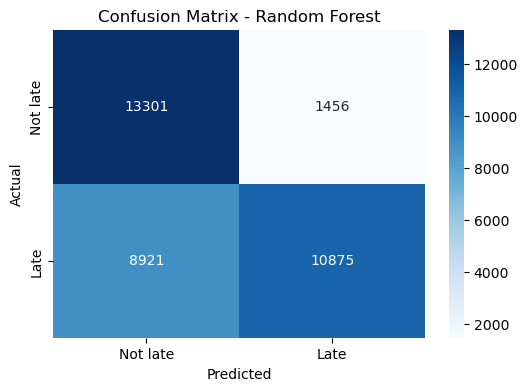

In [15]:
best_model_name = results.iloc[0]["Model"]

best_predictions = predictions_dict[best_model_name]

print("Best model based on F1-score:", best_model_name)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not late", "Late"],
    yticklabels=["Not late", "Late"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - " + best_model_name)
plt.show()

## 14. Feature importance
For the tree models, feature importance gives a simple indication of which encoded inputs the model used most. It does not prove that a feature causes delivery delays.

,Feature,Importance
0,Days_for_shipment_(scheduled),0.474348
99,Shipping_Mode_Standard Class,0.348469
98,Shipping_Mode_Second Class,0.086712
97,Shipping_Mode_Same Day,0.052306
5,Order_Item_Total,0.005498
1,Order_Item_Discount,0.005306
2,Order_Item_Discount_Rate,0.004126
3,Order_Item_Product_Price,0.002024
6,Product_Price,0.001816
4,Order_Item_Quantity,0.001316


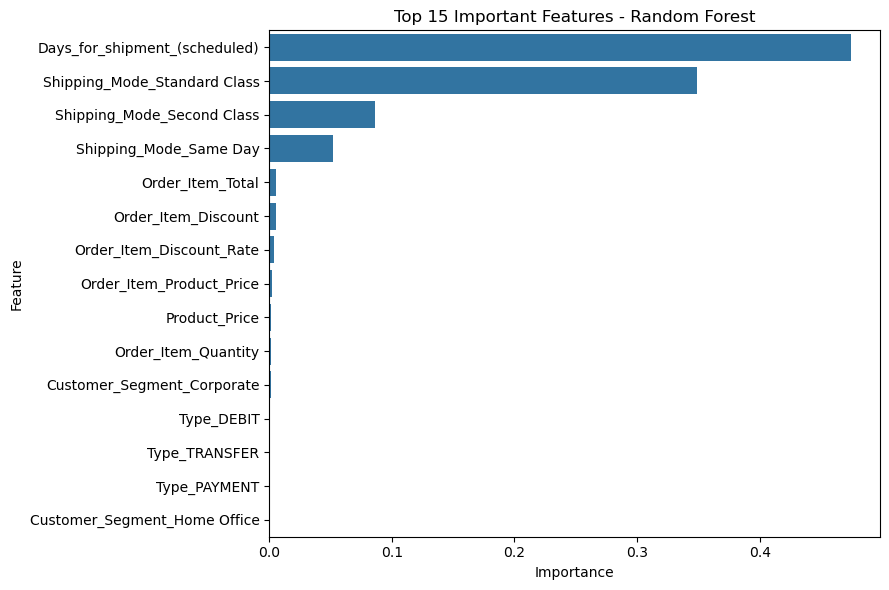

In [16]:
if best_model_name == "Decision Tree":
    importance_values = tree_model.feature_importances_
elif best_model_name == "Random Forest":
    importance_values = rf_model.feature_importances_
else:
    importance_values = None

if importance_values is not None:
    importance = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": importance_values
    }).sort_values("Importance", ascending=False)

    display(importance.head(20))

    plt.figure(figsize=(9, 6))
    sns.barplot(
        data=importance.head(15),
        x="Importance",
        y="Feature"
    )
    plt.title("Top 15 Important Features - " + best_model_name)
    plt.tight_layout()
    plt.show()
else:
    print("The selected model is Logistic Regression. We will interpret its coefficients in a later learning task.")

## 15. Generate predictions for sample records
This demonstrates how to use a trained model to predict late-delivery risk for records with the same feature columns.

In [17]:
# Use the trained Random Forest model for this demonstration.
# Replace sample_records with new records that contain the same feature columns.
sample_records = X_test.head(10)

sample_probabilities = rf_model.predict_proba(sample_records)[:, 1]
sample_predictions = rf_model.predict(sample_records)

prediction_result = pd.DataFrame({
    "Predicted_Late": sample_predictions,
    "Late_Probability": sample_probabilities
}, index=sample_records.index)

prediction_result["Risk_Level"] = np.where(
    prediction_result["Late_Probability"] >= 0.70,
    "High",
    np.where(prediction_result["Late_Probability"] >= 0.40, "Medium", "Low")
)

display(prediction_result)

,Predicted_Late,Late_Probability,Risk_Level
136492,0,0.332430,Low
45330,0,0.331634,Low
163514,0,0.352552,Low
142134,1,0.804446,High
89873,0,0.319763,Low
159385,0,0.350520,Low
37410,1,0.750832,High
23875,0,0.332501,Low
45627,0,0.327051,Low
154559,0,0.329240,Low


## 16. Save the trained model and results

The model is saved using `joblib`. The encoded feature columns must remain consistent when predicting on genuinely new data.

In [18]:
import joblib
import os

os.makedirs("ml_outputs", exist_ok=True)

joblib.dump(rf_model, "ml_outputs/dataco_random_forest_model.pkl")
results.to_csv("ml_outputs/model_comparison.csv", index=False)
prediction_result.to_csv("ml_outputs/sample_predictions.csv")

print("Model and result files saved in the ml_outputs folder.")

Model and result files saved in the ml_outputs folder.
